In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as T

from pathlib import Path
from torch.utils.data import DataLoader, Subset
from torchvision.models import resnet18, ResNet18_Weights

import zipfile

import matplotlib.pyplot as plt

from PIL import Image
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

from sklearn.metrics import accuracy_score

from sklearn.metrics import confusion_matrix, f1_score

import json
from collections import Counter

import time

In [2]:
with zipfile.ZipFile("../Weather Image Recognition.zip") as archive:
    archive.extractall("../images/weather")

In [3]:
device = torch.device("cpu")
# device = "cuda" if torch.cuda.is_available() else "cpu"

# преобразование изображений в тензор

In [4]:
train_transform = T.Compose([
    T.Resize((224, 224)),
    T.RandomHorizontalFlip(), # это случайное горизонтальное отражение
    T.ToTensor(),
    T.Normalize( # нормализация изображения (преобразует значение пикселей x_new = (x - mean)/std)
        mean=[0.485, 0.456, 0.406], # средние значения каналов RGB для изображений 
        std=[0.229, 0.224, 0.225] # это стандартные отклонения трёх цветовых каналов RGB для изображений
    )
])

valid_transform = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# загрузка datasets

In [ ]:
# создаём два способа читать одну и ту же коллекцию
train_dataset = torchvision.datasets.ImageFolder( # dataset - объект, который знает где находятся данные 
    # и как их подготовить для нейросети
    "../images/weather/dataset",
    transform=train_transform # train_dataset — содержит изображения с трансформациями для обучения
)

valid_dataset = torchvision.datasets.ImageFolder(
    "../images/weather/dataset",
    transform=valid_transform # valid_dataset — содержит те же изображения, но с трансформациями для проверки
)

In [6]:
class_names = train_dataset.classes
print("Классы:", class_names)
print("Количество классов:", len(class_names))
print("Всего изображений:", len(train_dataset))

Классы: ['dew', 'fogsmog', 'frost', 'glaze', 'hail', 'lightning', 'rain', 'rainbow', 'rime', 'sandstorm', 'snow']
Количество классов: 11
Всего изображений: 6862


# делим обучающую модель на train и valid

In [7]:
# Фиксируем случайность
torch.manual_seed(42)  # устаналиваю фиксированное значение генератора случайных чисел PyTorch

# Перемешиваем индексы изображений и создаём случайную последовательность
indices = torch.randperm(len(train_dataset)).tolist() # (создаёт случайную
#  поседовательность(len(изображения)).преобразует тензор в список))

# Разделяем: 80% на обучение, 20% на проверку
split = int(0.8 * len(indices)) # превращаем результат в число (берём 80% изображений * считаем кол-во индексов())


In [8]:
# Создаём обучающую и валидационную выборки
train_dataset = Subset(train_dataset, indices[:split]) # Subset создаёт подмножество исходного датасета, 
# выбирая элементы по указанным индексам
# PyTorch берёт исходный train_dataset и оставляет в новой выборке только фотографии с индексами из train_indices
valid_dataset = Subset(valid_dataset, indices[split:])
print(len(train_dataset))
print(len(valid_dataset))

5489
1373


# создание загрузичка данных - DataLoader

In [9]:
train_loader = DataLoader( # dataloader - чтобы удобно и порциями передавать данные
    train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=0 # num_workers=0 — загружаем данные в основном процессе, без дополнительных процессов
    # Основной процесс Python сам загружает изображения и готовит их для модели. Дополнительных работников нет.
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0 # num_workers=0 — загружаем данные в основном процессе, без дополнительных процессов
)

# загрузка предварительно обученной модели ResNet18

In [18]:
weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=weights)

# замораживание слоёв

In [19]:
for param in model.parameters():
    param.requires_grad = False # мы проходим по всем параметрам ResNet18 и замораживаем их

# замена последнего слоя

In [ ]:
# model

In [15]:
# num_classes = len(train_dataset.dataset.classes)
# print(num_classes)

11


In [20]:
model.fc = torch.nn.Linear(in_features=512, out_features=len(class_names))

In [21]:
model = model.to(device)

# создание функции потерь и оптимизатора

In [22]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.fc.parameters(), lr=0.001)

In [23]:
# проверяем подключен ли новый классификационный слой model.fc к оптимизатору
print(optimizer.param_groups[0]["params"][0] is model.fc.weight)
# optimizer.param_groups[0] — берём первую группу параметров, которыми управляет оптимизатор
# ["params"] — получаем список параметров, которые оптимизатор будет обновлять
# [0] — берём первый параметр из этого списка
# model.fc.weight — берём веса нашего последнего слоя нейросети
# is — проверяем, является ли это один и тот же объект
# если оптимизатор создан до замены слоя он сохраняе ссылки на старые параметры
# и новые веса model.fc не обновляются во время обучения

True


In [24]:
print(model.fc)

Linear(in_features=512, out_features=11, bias=True)


# обучение и проверка модели

In [25]:
start_time = time.time() # сохраняем время обучения

In [26]:
train_losses, valid_losses = [], []
train_accs, valid_accs = [], []

for epoch in range(3):
    model.eval() # переводит модель в режим оценки
    model.fc.train() # в режим обучения
    train_loss = train_correct = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = model(images)
        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * len(labels)
        predicted = logits.argmax(dim=1)
        train_correct += (predicted == labels).sum().item()

    valid_loss = valid_correct = 0

    with torch.inference_mode():
        for images, labels in valid_loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)
            valid_loss += criterion(logits, labels).item() * len(labels)

            predicted = logits.argmax(dim=1)
            valid_correct += (predicted == labels).sum().item()

    train_losses.append(train_loss / len(train_dataset))
    valid_losses.append(valid_loss / len(valid_dataset))
    train_accs.append(train_correct / len(train_dataset))
    valid_accs.append(valid_correct / len(valid_dataset))

    print(f"Эпоха {epoch + 1}: "
          f"train loss={train_losses[-1]:.3f}, val loss={valid_losses[-1]:.3f}, "
          f"train acc={train_accs[-1]:.1%}, val acc={valid_accs[-1]:.1%}")

Эпоха 1: train loss=1.192, val loss=0.698, train acc=66.2%, val acc=80.0%
Эпоха 2: train loss=0.589, val loss=0.544, train acc=83.3%, val acc=83.1%
Эпоха 3: train loss=0.478, val loss=0.480, train acc=85.9%, val acc=84.3%


In [27]:
training_time = time.time() - start_time

print(f"Время обучения: {training_time:.2f} секунд")

Время обучения: 527.07 секунд


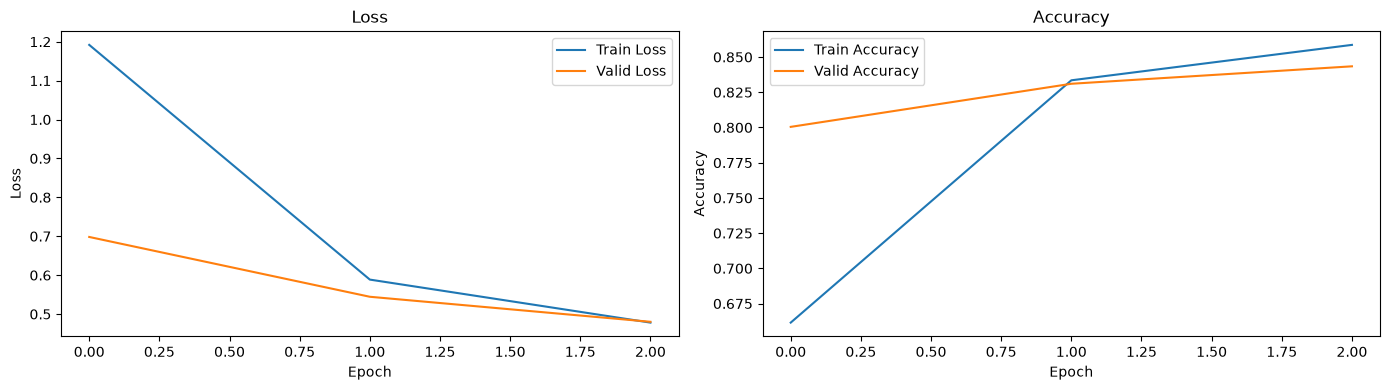

In [28]:
plt.figure(figsize=(14, 4))

plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.plot(valid_losses, label='Valid Loss')
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(train_accs, label='Train Accuracy')
plt.plot(valid_accs, label='Valid Accuracy')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

# сохранение модели

In [29]:
torch.save({
    'model_state_dict': model.state_dict(),
    'class_names': class_names
}, '../models/weather_resnet18.pth')

# проверяем модель на отдельном изображении, которого она раньше не видела

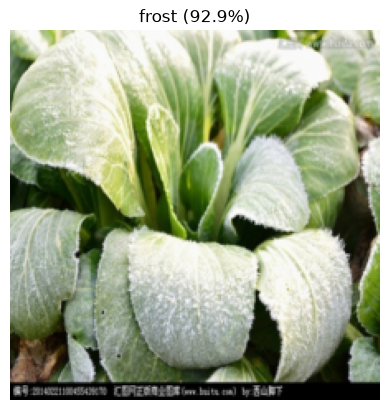

In [41]:
# загружаем изображение
image, label = valid_dataset[325]

x = image.unsqueeze(0).to(device)

# делаем предсказание
model.eval()
with torch.inference_mode():
    probabilities = torch.softmax(model(x), dim=1)
    predicted = probabilities.argmax(dim=1).item()

predicted_class = class_names[predicted]
confidence = probabilities[0, predicted].item()

image_to_show = image.permute(1, 2, 0).numpy().copy()

mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

for channel in range(3):
    image_to_show[:, :, channel] = (
        image_to_show[:, :, channel] * std[channel] + mean[channel]
    )

plt.imshow(image_to_show.clip(0, 1))
plt.title(f"{predicted_class} ({confidence:.1%})")
plt.axis("off")
plt.show()

# расчёт метрик

In [31]:
# Получаем предсказания на валидационной выборке
y_true = []
y_pred = []

model.eval()

with torch.inference_mode():
    for images, labels in valid_loader:
        images = images.to(device)

        outputs = model(images)
        predicted = outputs.argmax(dim=1)

        y_true.extend(labels.numpy())
        y_pred.extend(predicted.cpu().numpy())


# Рассчитываем метрики
f1 = f1_score(
    y_true,
    y_pred,
    average="weighted"
)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(len(class_names))
)


# Распределение изображений по классам
base_dataset = train_dataset.dataset

class_counts = Counter(base_dataset.targets)

class_distribution = {
    class_names[i]: class_counts[i]
    for i in range(len(class_names))
}

metrics = {
    "train_losses": train_losses,
    "valid_losses": valid_losses,
    "train_accs": train_accs,
    "valid_accs": valid_accs,
    "training_time": training_time,
    "dataset_size": len(base_dataset),
    "train_size": len(train_dataset),
    "valid_size": len(valid_dataset),
    "class_names": class_names,
    "class_distribution": class_distribution,
    "f1_score": float(f1),
    "confusion_matrix": cm.tolist()
}


with open("../models/weather_metrics.json", "w", encoding="utf-8") as file:
    json.dump(metrics, file, ensure_ascii=False, indent=4)

print(f"F1-score: {f1:.3f}")

F1-score: 0.841


$$F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}$$

показывает баланс между точностью (Precision) и полнотой (Recall)

$$Precision = \frac{TP}{TP + FP}$$
точность - какая доля предсказаний модели о принадлежности к определённому классу оказалась правильной

$$Recall = \frac{TP}{TP + FN}$$
полнота - какую долю всех реальных объектов определённого класса модель смогла найти

# матрица ошибок

узнаём какие классы погоды модель распознаёт хорошо, а какие путает

In [32]:
# получаем предсказания для всей валидационной выборки
y_true = []
y_pred = []

model.eval()

with torch.inference_mode():
    for images, labels in valid_loader:
        images = images.to(device)

        outputs = model(images)
        predicted = outputs.argmax(dim=1)

        y_true.extend(labels.numpy())
        y_pred.extend(predicted.cpu().numpy())

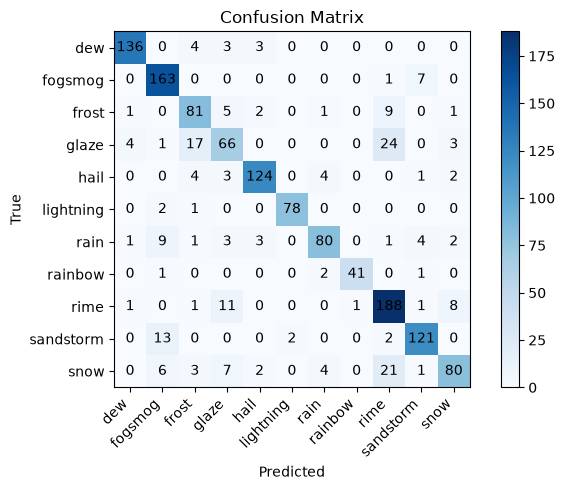

In [33]:
# строим матрицу ошибок
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7, 5))
plt.imshow(cm, cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('True')

plt.xticks(range(len(class_names)), class_names, rotation=45, ha='right')
plt.yticks(range(len(class_names)), class_names)

for i in range(len(class_names)):
    for j in range(len(class_names)):
        plt.text(j, i, cm[i, j], ha='center', va='center', color='black')

plt.colorbar()
plt.tight_layout()
plt.show()

In [24]:
# истинный класс sandstorm модель сказала что это 16 туманов (fogsmog)
# fogsmog - туман, dew - роса, rime - иней, hail - град

In [ ]:
# отчёт по качеству классификации
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))
# precision - насколько правильны предсказания этого класса
# recall - сколько реальных объектов класса найдено
# f1-score -баланс Precision и Recall
# support - сколько реальных фотографий этого класса было в проверочной выборке

              precision    recall  f1-score   support

         dew       0.95      0.93      0.94       146
     fogsmog       0.84      0.95      0.89       171
       frost       0.72      0.81      0.76       100
       glaze       0.67      0.57      0.62       115
        hail       0.93      0.90      0.91       138
   lightning       0.97      0.96      0.97        81
        rain       0.88      0.77      0.82       104
     rainbow       0.98      0.91      0.94        45
        rime       0.76      0.89      0.82       211
   sandstorm       0.89      0.88      0.88       138
        snow       0.83      0.65      0.73       124

    accuracy                           0.84      1373
   macro avg       0.86      0.84      0.84      1373
weighted avg       0.85      0.84      0.84      1373



# общая точность модели на валидационной выборке

In [35]:
# считаем Accuracy - 
accuracy = accuracy_score(y_true, y_pred)
print(f"Долю правильно классифицированных изображений среди всех изображений: {accuracy:.2%}")

Долю правильно классифицированных изображений среди всех изображений: 84.34%
